# Lab 4: Neural models
Source: [neur_models_lab_ex.pdf](neur_models_lab_ex.pdf). Tasks follow the sheet's order.

LLM assistance: Codex prepared the code and concise written answers; saved outputs record executed checks. The accompanying short report is [report.md](report.md).


## Task 1: Understand the problem before coding
Input space: `X = {0,1}²`. Output space: `Y = {0,1}`.
Examples: `(0,0) -> 0`, `(0,1) -> 1`, `(1,0) -> 1`, `(1,1) -> 0`.
The classes occupy opposite corners, and their convex hulls meet at the center, so a straight boundary cannot separate them.
An affine layer followed by sigmoid still has a linear decision boundary and cannot classify all four XOR examples correctly.

**Think about it:** XOR tests whether nonlinearity provides a representation that affine-only depth cannot express.


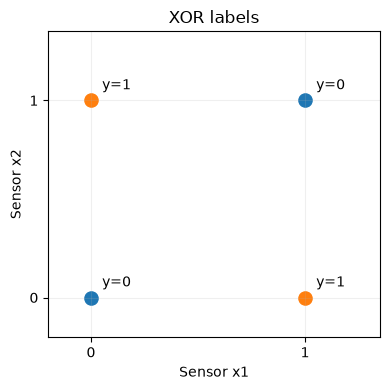

In [1]:
import numpy as np
import matplotlib.pyplot as plt

inputs = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=np.float32)
labels = np.array([0, 1, 1, 0], dtype=np.float32)
fig, ax = plt.subplots(figsize=(4, 4))
for point, label in zip(inputs, labels):
    ax.scatter(*point, color="tab:orange" if label else "tab:blue", s=90)
    ax.annotate(f"y={int(label)}", point, xytext=(8, 8), textcoords="offset points")
ax.set(xlabel="Sensor x1", ylabel="Sensor x2", title="XOR labels",
       xticks=[0, 1], yticks=[0, 1], xlim=(-0.2, 1.35), ylim=(-0.2, 1.35))
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## Task 2: Design the intelligent agent
Model: `2 inputs -> Linear(2,2) -> tanh -> Linear(2,1) -> sigmoid probability`.
Train logits with `BCEWithLogitsLoss` and full-batch Adam on CPU.
Hidden nonlinearity permits a nonlinear boundary; sigmoid models a binary probability and BCE penalizes incorrect binary predictions.

Success requires: final loss below 0.05 and lower than initial loss; all four thresholded labels correct; finite nonzero early gradients.
Use seed 0, 3,000 steps, learning rate 0.05, and a 0.5 prediction threshold.

**Think about it:** backpropagation sends the output-loss signal through the hidden layer. Gradients and initialization determine its learned features without hidden-unit target labels.


## Task 3: Generate a first implementation
**Implementation prompt used for this LLM-assisted submission:**

> Generate minimal readable PyTorch CPU code for X=[[0,0],[0,1],[1,0],[1,1]] and y=[[0],[1],[1],[0]]. Keep exactly a 2-2-1 network with tanh hidden activation and a linear output trained with BCEWithLogitsLoss. Use random initialization, seed 0, full-batch Adam with learning rate 0.05 for 3000 steps. Expose the initial/final loss, four sigmoid probabilities, thresholded predictions, and first-layer gradients after backward. Provide a configurable hidden activation and a zero-parameter initialization option for the later sheet experiments without changing the architecture. Save identical settings across activation comparisons.

Inspection: `model(x)` is the forward pass; `loss_fn(logits, targets)` creates the scalar loss; `loss.backward()` invokes reverse-mode AD; `optimizer.step()` changes parameters.
No corrective edits were needed before the submitted implementation was executed; gradient logging and activation selection were included in the specification.

**Think about it:** shapes, activation/loss choices, and seed handling can be inspected in code. Convergence, predictions, and gradient magnitudes require execution.


In [2]:
import torch
from torch import nn

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
torch.set_printoptions(precision=6, sci_mode=False)
x = torch.from_numpy(inputs)
y = torch.from_numpy(labels).reshape(-1, 1)
print("PyTorch:", torch.__version__, "NumPy:", np.__version__, "Device: CPU")


class NeuralAgent(nn.Module):
    def __init__(self, activation="tanh", outputs=1):
        super().__init__()
        self.hidden = nn.Linear(2, 2)
        self.activation = {"sigmoid": nn.Sigmoid, "tanh": nn.Tanh, "relu": nn.ReLU}[activation]()
        self.output = nn.Linear(2, outputs)

    def forward(self, inputs):
        return self.output(self.activation(self.hidden(inputs)))


def train(activation="tanh", zero=False, outputs=1, targets=y, steps=3000):
    torch.manual_seed(0)
    model = NeuralAgent(activation, outputs)
    if zero:
        with torch.no_grad():
            for parameter in model.parameters():
                parameter.zero_()  # Zero biases too, ensuring exact hidden-unit symmetry.
    initial_parameters = {name: value.detach().clone() for name, value in model.named_parameters()}
    loss_fn = nn.BCEWithLogitsLoss() if outputs == 1 else nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.05)
    initial_loss = loss_fn(model(x), targets).item()
    losses = []
    snapshots = {0: model.hidden.weight.detach().clone()}
    for step in range(steps):
        optimizer.zero_grad()
        logits = model(x)  # Forward pass.
        loss = loss_fn(logits, targets)  # Mean scalar loss.
        loss.backward()  # Reverse-mode automatic differentiation.
        if step == 0:
            early_gradient = model.hidden.weight.grad.detach().clone()
        optimizer.step()  # Parameter update.
        losses.append(loss.item())
        if step + 1 in {1, 10, 100, 1000, 3000}:
            snapshots[step + 1] = model.hidden.weight.detach().clone()
    with torch.no_grad():
        final_logits = model(x)
        final_loss = loss_fn(final_logits, targets).item()
        probabilities = final_logits.sigmoid() if outputs == 1 else final_logits.softmax(dim=1)
        predictions = (probabilities >= 0.5).long() if outputs == 1 else probabilities.argmax(dim=1)
    return {
        "model": model, "initial_loss": initial_loss, "final_loss": final_loss,
        "probabilities": probabilities, "predictions": predictions,
        "early_gradient": early_gradient, "losses": losses,
        "snapshots": snapshots, "initial_parameters": initial_parameters,
    }


PyTorch: 2.14.1+cpu NumPy: 2.3.5 Device: CPU


## Task 4: Execute, test, and diagnose
### Part A: Basic learning check
The baseline keeps the specified dataset and 2-2-1 architecture. No tuning is needed if its checks pass.


Initial loss: 0.715159
Final loss:   0.000083
Input       Probability  Prediction  Target
[0, 0]      0.000059     0           0
[0, 1]      0.999899     1           1
[1, 0]      0.999877     1           1
[1, 1]      0.000051     0           0
Learning checks passed: lower loss, 4/4 correct, finite nonzero early gradient.


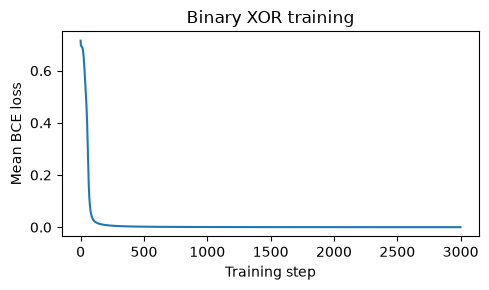

In [3]:
binary = train()
print(f"Initial loss: {binary['initial_loss']:.6f}")
print(f"Final loss:   {binary['final_loss']:.6f}")
print("Input       Probability  Prediction  Target")
for point, probability, prediction, target in zip(x, binary["probabilities"], binary["predictions"], y):
    print(f"{point.int().tolist()}      {probability.item():.6f}     {prediction.item()}           {int(target.item())}")
assert binary["final_loss"] < 0.05 and binary["final_loss"] < binary["initial_loss"]
assert torch.equal(binary["predictions"], y.long())
assert torch.isfinite(binary["early_gradient"]).all() and binary["early_gradient"].norm() > 0
print("Learning checks passed: lower loss, 4/4 correct, finite nonzero early gradient.")

plt.figure(figsize=(5, 3))
plt.plot(binary["losses"])
plt.xlabel("Training step")
plt.ylabel("Mean BCE loss")
plt.title("Binary XOR training")
plt.tight_layout()
plt.show()


### Part B: Backpropagation check
`hidden.weight.grad` is the matrix `dL/dW¹` computed by the chain rule through the output and tanh layers.
Since loss reduction is a mean over four examples, its gradient is the mean of the four example gradients. The numerical check below tests that equality.


In [4]:
print("First-step first-layer gradient:\n", binary["early_gradient"])
model = binary["model"]
model.zero_grad()
mean_loss = nn.BCEWithLogitsLoss()(model(x), y)
mean_loss.backward()
batch_gradient = model.hidden.weight.grad.detach().clone()
individual_gradients = []
for row in range(4):
    example_loss = nn.BCEWithLogitsLoss()(model(x[row:row+1]), y[row:row+1])
    gradient, = torch.autograd.grad(example_loss, model.hidden.weight)
    individual_gradients.append(gradient)
average_gradient = torch.stack(individual_gradients).mean(dim=0)
assert torch.allclose(batch_gradient, average_gradient, atol=1e-7, rtol=1e-5)
print("Final first-layer gradient:\n", batch_gradient)
print("Batch gradient equals mean example gradient:", torch.allclose(batch_gradient, average_gradient))


First-step first-layer gradient:
 tensor([[ 0.000505,  0.000607],
        [-0.042569, -0.044773]])
Final first-layer gradient:
 tensor([[ 0.000003, -0.000004],
        [-0.000006,  0.000003]])
Batch gradient equals mean example gradient: True


### Part C: Symmetry experiment
Keep the architecture and training settings, but set every weight and bias to zero.


In [5]:
symmetric = train(zero=True)
for step, weights in symmetric["snapshots"].items():
    identical = torch.equal(weights[0], weights[1])
    print(f"Step {step}: rows = {weights.tolist()}, identical = {identical}")
    assert identical
print(f"Zero-initialized final loss: {symmetric['final_loss']:.6f}")
print("Probabilities:", symmetric["probabilities"].flatten().tolist())
print("Correct labels:", int((symmetric["predictions"] == y).sum()), "/ 4")


Step 0: rows = [[0.0, 0.0], [0.0, 0.0]], identical = True
Step 1: rows = [[0.0, 0.0], [0.0, 0.0]], identical = True
Step 10: rows = [[0.0, 0.0], [0.0, 0.0]], identical = True
Step 100: rows = [[0.0, 0.0], [0.0, 0.0]], identical = True
Step 1000: rows = [[0.0, 0.0], [0.0, 0.0]], identical = True
Step 3000: rows = [[0.0, 0.0], [0.0, 0.0]], identical = True
Zero-initialized final loss: 0.693147
Probabilities: [0.5, 0.5, 0.5, 0.5]
Correct labels: 2 / 4


Identical hidden units compute the same output and receive the same gradients, so deterministic updates preserve identical rows. In this fully zero, balanced XOR experiment, gradients are zero and probabilities stay at 0.5. Random initialization breaks this symmetry.

### Part D: Activation experiment
Change only the hidden activation. Seed, initial parameter tensors, data, architecture, optimizer, learning rate, and step count stay fixed.


In [6]:
activation_results = {"sigmoid": train("sigmoid"), "tanh": binary, "relu": train("relu")}
print(f"{'Activation':<12} {'Final loss':<12} {'Correct':<10} {'Early gradient norm':<20}")
for name, result in activation_results.items():
    for parameter, values in binary["initial_parameters"].items():
        assert torch.equal(values, result["initial_parameters"][parameter])
    correct = int((result["predictions"] == y).sum())
    gradient_norm = result["early_gradient"].norm().item()
    print(f"{name:<12} {result['final_loss']:<12.6f} {str(correct) + '/4':<10} {gradient_norm:<20.6f}")


Activation   Final loss   Correct    Early gradient norm 
sigmoid      0.477423     3/4        0.000891            
tanh         0.000083     4/4        0.061785            
relu         0.693149     2/4        0.001699            


For these settings, tanh learns all four labels; sigmoid and ReLU do not. Tanh has a larger early gradient here. Sigmoid derivatives can be small, while negative ReLU pre-activations have zero derivatives; initialization and optimization also affect convergence. These four examples and one seed do not establish a universally best activation.

**Think about it:** inspect both pre-activations and outputs. Large-magnitude sigmoid pre-activations with outputs near 0 or 1 indicate saturation; ReLU outputs of zero with negative pre-activations indicate inactive units.


In [7]:
for name in ["sigmoid", "relu"]:
    trained_model = activation_results[name]["model"]
    with torch.no_grad():
        preactivations = trained_model.hidden(x)
        activations = trained_model.activation(preactivations)
    print(name, "final pre-activations:\n", preactivations)
    print(name, "final activations:\n", activations)


sigmoid final pre-activations:
 tensor([[  0.917995,  -2.035920],
        [-11.182744,  11.833183],
        [-11.094411,  11.873359],
        [-23.195148,  25.742462]])
sigmoid final activations:
 tensor([[0.714633, 0.115483],
        [0.000014, 0.999993],
        [0.000015, 0.999993],
        [0.000000, 1.000000]])
relu final pre-activations:
 tensor([[-0.431100, -0.400856],
        [-0.210532, -0.921243],
        [-0.557697, -0.982836],
        [-0.337129, -1.503224]])
relu final activations:
 tensor([[0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.]])


## Task 5: Three-class extension
Targets: `(0,0) -> 0`, `(0,1)/(1,0) -> 1`, `(1,1) -> 2`.
Keep two tanh hidden units, replace the output with three logits, and use multiclass cross-entropy.

**Predictions before execution:** output weights have shape `(3,2)` and each example has three logits. Softmax divides each positive exponential by their sum, so probabilities sum to one. Combining softmax with cross-entropy gives the per-example logit gradient `p - one_hot(y)`; a four-example mean adds a factor of `1/4`.

**Modification prompt:**

> Modify only the output/loss portion of the previous model for labels [0,1,1,2]: use Linear(2,3) logits and CrossEntropyLoss. Keep the two tanh hidden units, initialization seed, full-batch Adam settings, and 3000 steps. Print all four class probability vectors and predictions; check softmax sums, invariance to adding 100 to every logit, and the p-minus-one-hot logit gradient with mean-loss scaling.


In [8]:
class_targets = torch.tensor([0, 1, 1, 2], dtype=torch.long)
multiclass = train(outputs=3, targets=class_targets)
assert multiclass["model"].output.weight.shape == (3, 2)
assert torch.equal(binary["initial_parameters"]["hidden.weight"],
                   multiclass["initial_parameters"]["hidden.weight"])
assert torch.equal(binary["initial_parameters"]["hidden.bias"],
                   multiclass["initial_parameters"]["hidden.bias"])
print(f"Initial loss: {multiclass['initial_loss']:.6f}; final loss: {multiclass['final_loss']:.6f}")
print("Input      Class probabilities                  Prediction Target")
for point, probabilities, prediction, target in zip(x, multiclass["probabilities"],
                                                    multiclass["predictions"], class_targets):
    values = [round(value, 6) for value in probabilities.tolist()]
    print(point.int().tolist(), values, prediction.item(), target.item())
probabilities = multiclass["probabilities"]
print("First example softmax vector:", probabilities[0])
print("First example probability sum:", probabilities[0].sum().item())
assert torch.allclose(probabilities.sum(dim=1), torch.ones(4), atol=1e-6)
assert torch.equal(multiclass["predictions"], class_targets)
assert multiclass["final_loss"] < multiclass["initial_loss"]

logits = multiclass["model"](x)
shifted = (logits.detach() + 100).softmax(dim=1)
maximum_change = (shifted - probabilities).abs().max().item()
assert torch.allclose(shifted, probabilities, atol=1e-6, rtol=1e-5)
print("Maximum probability change after +100:", maximum_change)

logits.retain_grad()
nn.CrossEntropyLoss()(logits, class_targets).backward()
expected = (logits.detach().softmax(dim=1) - nn.functional.one_hot(class_targets, 3)) / 4
assert torch.allclose(logits.grad, expected, atol=1e-7, rtol=1e-5)
print("First example mean-loss logit gradient:", logits.grad[0])
print("Expected (p - one_hot(y)) / 4:", expected[0])
print("Three-class validation passed: 4/4 correct, normalized probabilities, correct logit gradient.")


Initial loss: 1.059108; final loss: 0.000039
Input      Class probabilities                  Prediction Target
[0, 0] [0.999951, 4.9e-05, 0.0] 0 0
[0, 1] [2.3e-05, 0.999969, 7e-06] 1 1
[1, 0] [2.3e-05, 0.99997, 7e-06] 1 1
[1, 1] [0.0, 4.5e-05, 0.999955] 2 2
First example softmax vector: tensor([0.999951, 0.000049, 0.000000])
First example probability sum: 0.9999999403953552
Maximum probability change after +100: 2.3283064365386963e-10
First example mean-loss logit gradient: tensor([-0.000012,  0.000012,  0.000000])
Expected (p - one_hot(y)) / 4: tensor([-0.000012,  0.000012,  0.000000])
Three-class validation passed: 4/4 correct, normalized probabilities, correct logit gradient.


Adding a common constant leaves softmax unchanged because it cancels between numerator and denominator. Stable implementations subtract the maximum logit before exponentiation to avoid overflow.

**Think about it:** large-vocabulary next-token prediction uses the same logits, softmax, cross-entropy, and `p-y` gradient. Context processing, embeddings, attention, depth, and the much larger output matrix change the surrounding architecture and cost.

## Reflection questions
1. Affine-only depth remains affine; XOR requires hidden nonlinearity.
2. Falling loss and four correct labels show that the baseline's gradients supplied a useful learning signal, beyond merely being nonzero.
3. Identical outputs and gradients preserve identical hidden parameters; zero initialization here leaves the model stuck at 0.5.
4. The measured early norms differ; activation derivatives explain possible gradient effects, while the exact magnitudes and failures are observations for this seed and optimizer.
5. A binary target needs a binary probability/loss pair; mutually exclusive classes need categorical logits and cross-entropy.
6. Codex reduced PyTorch boilerplate; verification was essential for checking correct labels, mean-gradient scaling, and failed activation runs.
7. Keep loss, prediction, finite-gradient, output-shape, and normalization checks. Exhaustive finite-difference checks become costly; use sampled checks on small subsets.
